# Lab 01 Tasks — Introductory Computer Vision Lab

Each task uses its own image from the `images/` folder (free stock photos from Unsplash via picsum.photos, and a Gutenberg Bible scan from Wikimedia Commons).

## Part 1: Environment Setup & Validation
### 1.1 Installation

In [1]:
# Install the libraries needed for this lab (run once).
# pandas is needed later in Task 9.
%pip install opencv-python matplotlib pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\azama\AppData\Local\Temp\claude\C--Users-azama-VS-Code-PROJECTS-01-Academic-Projects-Computer-Vision\a3c19062-200d-4788-a4f3-77cf48e11a00\scratchpad\venv\Scripts\python.exe -m pip install --upgrade pip


### 1.2 Import & Validate

OpenCV version: 5.0.0
Matplotlib version: 3.11.2


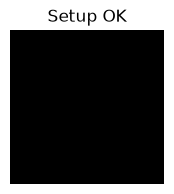

In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Validation: if these lines print a version, the library is installed and working.
print("OpenCV version:", cv2.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)

# Quick functional test: create a tiny black image and show it with matplotlib.
test_img = np.zeros((50, 50, 3), dtype=np.uint8)
plt.figure(figsize=(2, 2))
plt.imshow(test_img)
plt.axis('off')
plt.title("Setup OK")
plt.show()

## Part 2: Python Data Structures & Logic
### Task 1: Object-Oriented Grocery Manager

In [3]:
class GroceryManager:
    """Keeps a grocery list where each item stores its quantity and unit price."""

    def __init__(self):
        # Dictionary: item name -> {'quantity': ..., 'price': ...}
        self.items = {}

    def add_item(self, item, quantity, price):
        # Adds a new item to the list (or overwrites it if it already exists).
        self.items[item] = {'quantity': quantity, 'price': price}
        print(f"Added {quantity} x {item} @ {price}")

    def remove_item(self, item):
        # Removes an item. Basic error handling: we cannot remove an item that is not in the list.
        if item not in self.items:
            print(f"Error: '{item}' is not in the list.")
            return
        del self.items[item]
        print(f"Removed {item}")

    def view_list(self):
        # Prints every item with its quantity and price.
        print("Grocery List:")
        for item, info in self.items.items():
            print(f"  {item}: qty={info['quantity']}, price={info['price']}")

    def calculate_total(self):
        # Total cost = sum of (quantity * price) for all items.
        return sum(info['quantity'] * info['price'] for info in self.items.values())


# Demo
gm = GroceryManager()
gm.add_item("Milk", 2, 250)
gm.add_item("Bread", 1, 180)
gm.add_item("Eggs", 12, 30)
gm.view_list()
gm.remove_item("Butter")   # does not exist -> error message
gm.remove_item("Bread")
gm.view_list()
print("Total cost:", gm.calculate_total())

Added 2 x Milk @ 250
Added 1 x Bread @ 180
Added 12 x Eggs @ 30
Grocery List:
  Milk: qty=2, price=250
  Bread: qty=1, price=180
  Eggs: qty=12, price=30
Error: 'Butter' is not in the list.
Removed Bread
Grocery List:
  Milk: qty=2, price=250
  Eggs: qty=12, price=30
Total cost: 860


### Task 2: Advanced Student Record System

In [4]:
# Nested dictionary: student ID -> {'Name', 'Major', 'Grades'}
students = {
    101: {'Name': 'Ali',    'Major': 'Computer Science', 'Grades': [85, 90, 78]},
    102: {'Name': 'Sara',   'Major': 'Mathematics',      'Grades': [92, 88, 95]},
    103: {'Name': 'Ahmed',  'Major': 'Computer Science', 'Grades': [70, 75, 80]},
    104: {'Name': 'Fatima', 'Major': 'Physics',          'Grades': [88, 91, 84]},
}


def top_student(records):
    # Returns the name of the student whose average grade is the highest.
    best_id = max(records, key=lambda sid: sum(records[sid]['Grades']) / len(records[sid]['Grades']))
    return records[best_id]['Name']


def search_by_major(records, major):
    # Prints every student enrolled in the given major.
    print(f"Students in {major}:")
    for sid, info in records.items():
        if info['Major'] == major:
            print(f"  {sid}: {info['Name']}")


print("Highest average:", top_student(students))
search_by_major(students, 'Computer Science')

Highest average: Sara
Students in Computer Science:
  101: Ali
  103: Ahmed


## Part 3: Core Computer Vision & Matplotlib
### Task 3: Safe Image Loading & RGB Visualization

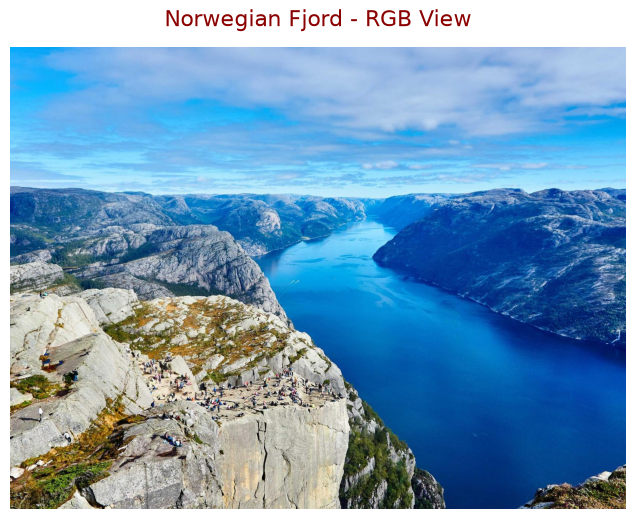

In [5]:
image_path = 'images/task3_fjord.jpg'
image = cv2.imread(image_path)   # OpenCV loads images in BGR order

# Safety check: imread returns None when the path is wrong.
if image is None:
    print("Error: Image not found.")
else:
    # Convert BGR -> RGB so Matplotlib shows the correct colors.
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(image_rgb)
    plt.axis('off')
    plt.title('Norwegian Fjord - RGB View', fontsize=16, color='darkred', pad=15)
    plt.show()

### Task 4: Interactive Geometry & Blank Canvas

Canvas center: (400, 400)


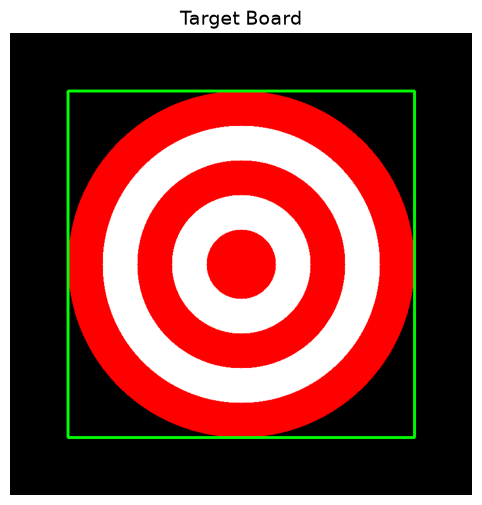

In [6]:
# 800x800 black canvas (3 channels so we can draw in color).
canvas = np.zeros((800, 800, 3), dtype=np.uint8)

# Exact center of the canvas: (width // 2, height // 2).
h, w = canvas.shape[:2]
center = (w // 2, h // 2)
print("Canvas center:", center)

# Target board: 5 filled concentric circles, drawn largest first so smaller ones sit on top.
colors = [(255, 0, 0), (255, 255, 255)]   # alternating red / white (RGB, since we plot with Matplotlib)
radii = [300, 240, 180, 120, 60]
for i, r in enumerate(radii):
    cv2.circle(canvas, center, r, colors[i % 2], -1)   # -1 = filled

# Bounding box around the outermost circle: from (center - r) to (center + r).
R = radii[0]
cv2.rectangle(canvas, (center[0] - R, center[1] - R), (center[0] + R, center[1] + R), (0, 255, 0), 3)

plt.figure(figsize=(6, 6))
plt.imshow(canvas)
plt.axis('off')
plt.title('Target Board', fontsize=14)
plt.show()

### Task 5: Advanced Blurring & NumPy ROI Extraction

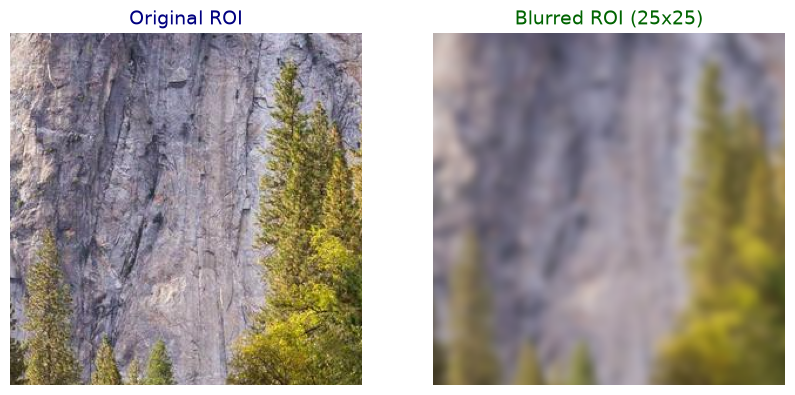

In [7]:
img = cv2.imread('images/task5_yosemite.jpg')
if img is None:
    print("Error: Image not found.")
else:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Heavy blur: larger kernel = stronger smoothing.
    blurred = cv2.GaussianBlur(img, (25, 25), 0)

    # 300x300 ROI from the exact center using NumPy slicing [rows, cols].
    cy, cx = img.shape[0] // 2, img.shape[1] // 2
    half = 150
    roi_original = img[cy - half:cy + half, cx - half:cx + half]
    roi_blurred = blurred[cy - half:cy + half, cx - half:cx + half]

    # Side-by-side comparison.
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(roi_original)
    plt.axis('off')
    plt.title('Original ROI', fontsize=14, color='navy')

    plt.subplot(1, 2, 2)
    plt.imshow(roi_blurred)
    plt.axis('off')
    plt.title('Blurred ROI (25x25)', fontsize=14, color='darkgreen')
    plt.show()

### Task 6: Alpha Blending & Typography

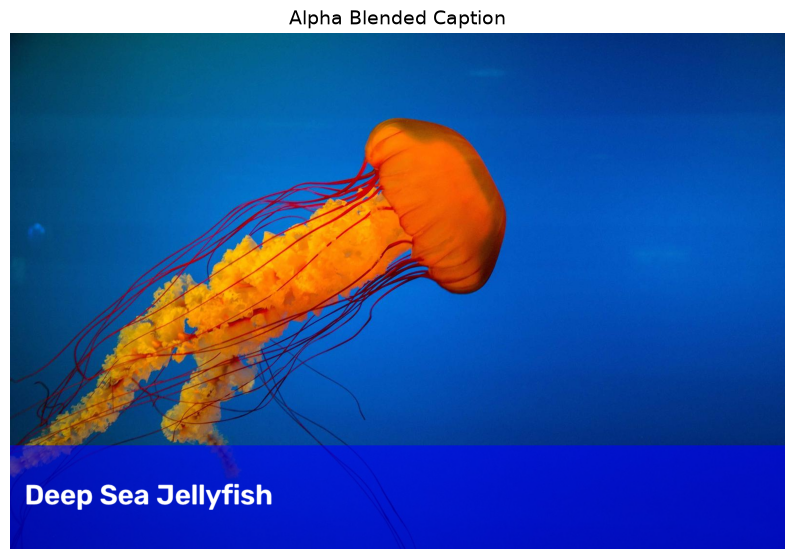

In [8]:
img = cv2.cvtColor(cv2.imread('images/task6_jellyfish.jpg'), cv2.COLOR_BGR2RGB)
h, w = img.shape[:2]

# Overlay = copy of the image with a solid blue box on the bottom 20%.
overlay = img.copy()
box_top = int(h * 0.8)
cv2.rectangle(overlay, (0, box_top), (w, h), (0, 0, 255), -1)   # blue in RGB

# Blend: 60% overlay + 40% original -> the blue box becomes semi-transparent.
blended = cv2.addWeighted(overlay, 0.6, img, 0.4, 0)

# Write the caption inside the transparent box.
cv2.putText(blended, 'Deep Sea Jellyfish', (30, box_top + (h - box_top) // 2 + 15),
            cv2.FONT_HERSHEY_SIMPLEX, 2, (255, 255, 255), 4)

plt.figure(figsize=(10, 7))
plt.imshow(blended)
plt.axis('off')
plt.title('Alpha Blended Caption', fontsize=14)
plt.show()

### Task 7: Matrix-Based Rotation & Adaptive Thresholding

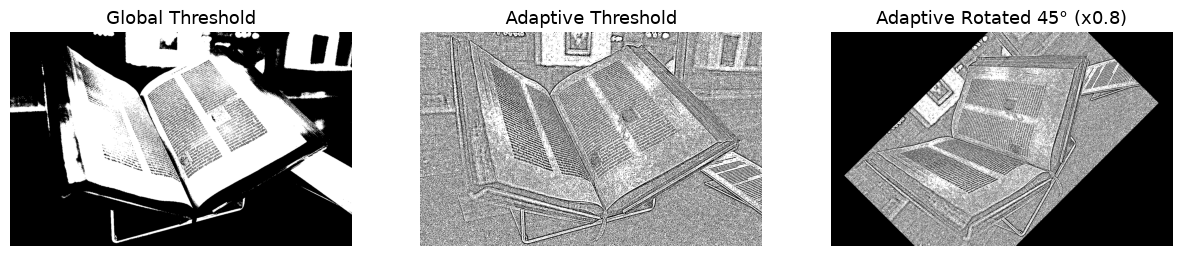

In [9]:
# Load directly as grayscale (flag 0).
gray = cv2.imread('images/task7_gutenberg_bible.jpg', cv2.IMREAD_GRAYSCALE)

# Global: one threshold (127) for the whole image.
_, global_th = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# Adaptive: threshold computed per 11x11 neighbourhood -> handles uneven lighting better.
adaptive_th = cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, 11, 2)

# Rotation matrix: rotate 45 degrees about the center and scale by 0.8 so corners stay visible.
h, w = adaptive_th.shape
M = cv2.getRotationMatrix2D((w // 2, h // 2), 45, 0.8)
rotated = cv2.warpAffine(adaptive_th, M, (w, h))

titles = ['Global Threshold', 'Adaptive Threshold', 'Adaptive Rotated 45° (x0.8)']
images = [global_th, adaptive_th, rotated]
plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.axis('off')
    plt.title(titles[i], fontsize=13)
plt.show()

### Task 8: Masking with Bitwise Logic

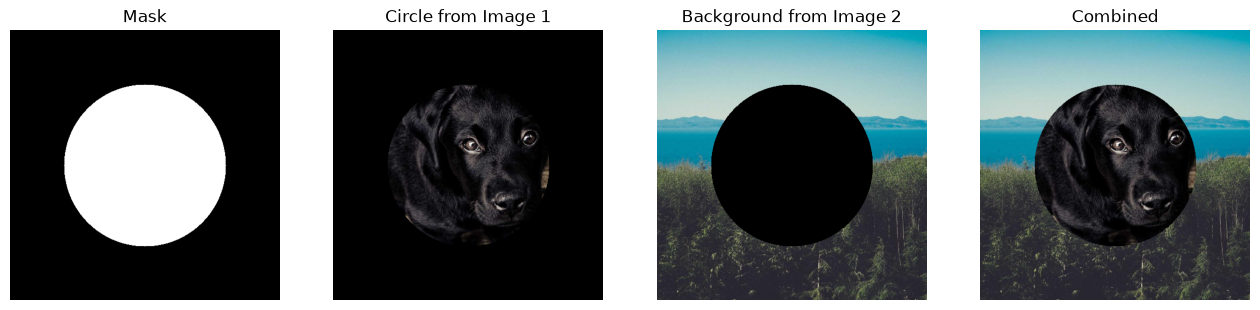

In [10]:
# Two different images resized to the same size (500x500) so pixel-wise ops are possible.
img1 = cv2.resize(cv2.cvtColor(cv2.imread('images/task8_puppy.jpg'), cv2.COLOR_BGR2RGB), (500, 500))
img2 = cv2.resize(cv2.cvtColor(cv2.imread('images/task8_forest_lake.jpg'), cv2.COLOR_BGR2RGB), (500, 500))

# Binary mask: black background with a white filled circle in the center.
mask = np.zeros((500, 500), dtype=np.uint8)
cv2.circle(mask, (250, 250), 150, 255, -1)

# Keep only the circle region from image 1.
fg = cv2.bitwise_and(img1, img1, mask=mask)

# Invert mask -> keep only the background (outside circle) from image 2.
mask_inv = cv2.bitwise_not(mask)
bg = cv2.bitwise_and(img2, img2, mask=mask_inv)

# Combine both parts into one image.
combined = cv2.bitwise_or(fg, bg)

titles = ['Mask', 'Circle from Image 1', 'Background from Image 2', 'Combined']
images = [mask, fg, bg, combined]
plt.figure(figsize=(16, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray' if i == 0 else None)
    plt.axis('off')
    plt.title(titles[i], fontsize=12)
plt.show()

### Task 9: Statistical Image Profiling with Pandas

In [11]:
img = cv2.cvtColor(cv2.imread('images/task9_strawberries.jpg'), cv2.COLOR_BGR2RGB)

# Split into channels (each is 2D), then flatten each to 1D.
red = img[:, :, 0].flatten()
green = img[:, :, 1].flatten()
blue = img[:, :, 2].flatten()

# One row per pixel, one column per channel.
df = pd.DataFrame({'Red': red, 'Green': green, 'Blue': blue})

# describe() gives count, mean, std, min, quartiles and max for each channel.
print(df.describe().round(2))   # round(2) avoids scientific notation

              Red       Green        Blue
count  1080000.00  1080000.00  1080000.00
mean       152.15       49.60       71.98
std         69.48       36.56       39.80
min          0.00        0.00        0.00
25%         96.00       25.00       38.00
50%        167.00       37.00       63.00
75%        209.00       67.00       96.00
max        255.00      249.00      255.00
